# Follower loads and unsymmetric matrices

Loads that depend on the configuration, such as follower (hydrostatic)
pressures, are supported through optional keyword arguments of the
callables of [Analysis](../analysis.rst), see
[callbacks](../callbacks.rst): `calc_fint`, `calc_kC` and `calc_kG`
receive the load factor `inc` when they declare it, and `calc_fext`
receives the current configuration `c`, returning the load vector
$-\partial \boldsymbol{R}/\partial \lambda$ used by the arc-length methods.
Their load stiffness makes the tangent stiffness matrix unsymmetric in
general (Schweizerhof and Ramm, 1984), which the solvers support:
[solve](../static.rst) and the non-linear solvers use LU factorizations,
[lb](../linear_buckling.rst) selects the solvers of unsymmetric matrices
when needed, `symmetric=None`, and [freq](../freq.rst) uses general
eigenvalue solvers by default.

The models are those of the tests `tests/test_follower_loads.py`,
`tests/test_inertia_unsymmetric.py`, `tests/test_follower_freq_static.py`
and `tests/test_linear_buckling_unsymmetric.py`, some of whose helper
functions are imported.

References: Schweizerhof, K., Ramm, E., Displacement dependent pressure
loads in nonlinear finite element analyses, Computers & Structures, 18(6),
1099-1114, 1984, https://doi.org/10.1016/0045-7949(84)90154-8; Ziegler, H.,
Die Stabilitätskriterien der Elastomechanik, Ingenieur-Archiv, 20(1),
49-56, 1952, https://doi.org/10.1007/BF00536796; Bolotin, V.V.,
Nonconservative Problems of the Theory of Elastic Stability, Pergamon
Press, Oxford, 1963.

In [1]:
%matplotlib inline
import os
import sys

# the helper functions of the tests are imported from the folder tests/
sys.path.insert(0, os.path.join('..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eig
from scipy.optimize import root
from scipy.sparse import csr_matrix

from structsolve import Analysis, freq, lb
from structsolve.linear_buckling import is_symmetric

from test_inertia_unsymmetric import LinearUnsymmetric, dense_count
from test_follower_freq_static import (K_SPRING, L_BAR, MASS,
                                       linear_follower_problem, ziegler)
from test_linear_buckling_unsymmetric import (FOLLOWER, load_follower,
                                              lowest_positive_real,
                                              relative_residuals)

def print_table(rows, header=('quantity', 'computed', 'reference', 'rel. diff.')):
    """Rows of (label, computed, reference); the relative difference is
    |computed - reference|/|reference|"""
    w = max(len(header[0]), max(len(r[0]) for r in rows))
    print(f'{header[0]:<{w}}  {header[1]:>16}  {header[2]:>16}  {header[3]:>10}')
    for label, comp, ref in rows:
        rel = abs(comp - ref)/abs(ref)
        print(f'{label:<{w}}  {comp:16.10g}  {ref:16.10g}  {rel:10.2e}')

## Non-linear analyses

Three hardening springs, $\boldsymbol{F}_{int}(\boldsymbol{c}) =
\boldsymbol{K} \boldsymbol{c} + \{a_i c_i^3\}$, under a load that depends
on the configuration,
$\boldsymbol{F}(\boldsymbol{c}, \lambda) = \lambda (\boldsymbol{q}_0 + \boldsymbol{Q} \boldsymbol{c})$,
with the unsymmetric load stiffness matrix
$\boldsymbol{K}_F = -\partial \boldsymbol{F}/\partial \boldsymbol{c} = -\lambda \boldsymbol{Q}$.
The residual and its derivatives are

$$
\boldsymbol{R} = \boldsymbol{F}_{int}(\boldsymbol{c}) - \lambda (\boldsymbol{q}_0 + \boldsymbol{Q} \boldsymbol{c}), \qquad
\boldsymbol{K}_T = \frac{\partial \boldsymbol{R}}{\partial \boldsymbol{c}} = \boldsymbol{K} + \mathrm{diag}(3 a_i c_i^2) - \lambda \boldsymbol{Q}, \qquad
-\frac{\partial \boldsymbol{R}}{\partial \lambda} = \boldsymbol{q}_0 + \boldsymbol{Q} \boldsymbol{c}
$$

`calc_fint(c, inc)` returns $\boldsymbol{F}_{int} - \lambda \boldsymbol{Q} \boldsymbol{c}$,
`calc_kC(c, NLgeom, inc)` the matrix $\boldsymbol{K}_T$ and
`calc_fext(inc, c)` the load vector $\lambda (\boldsymbol{q}_0 + \boldsymbol{Q} \boldsymbol{c})$
of the configuration, with the matrices of `make_problem` of
`tests/test_follower_loads.py`:

In [2]:
class FollowerProblem(object):
    def __init__(self, K, a, q0, Q, with_c=True):
        self.K = K
        self.a = a
        self.q0 = q0
        self.Q = Q
        self.with_c = with_c
        self.an = None
        # (inc, ||R||/||lbd*q||, number of converged increments) of each
        # calc_fint call
        self.calls = []

    def fint_el(self, c):
        return self.K @ c + self.a*c**3

    def residual(self, c, lbd):
        return self.fint_el(c) - lbd*(self.q0 + self.Q @ c)

    def calc_fext(self, inc=1., silent=True, c=None):
        if c is None:
            return inc*self.q0
        return inc*(self.q0 + self.Q @ c)

    def calc_fint(self, c, inc=1., silent=True):
        R = self.residual(c, inc)
        ref = max(np.linalg.norm(inc*(self.q0 + self.Q @ c)), 1e-300)
        step = len(self.an.increments) if self.an is not None else 0
        self.calls.append((inc, np.linalg.norm(R)/ref, step))
        return self.fint_el(c) - inc*(self.Q @ c)

    def calc_kC(self, c=None, NLgeom=False, inc=1., silent=True):
        if not NLgeom:
            return csr_matrix(self.K)
        return csr_matrix(self.K + np.diag(3*self.a*c**2) - inc*self.Q)

    def calc_kG(self, c=None, NLgeom=False, silent=True):
        return csr_matrix(self.K.shape)

    def analysis(self, **kwargs):
        if self.with_c:
            calc_fext = self.calc_fext
        else:
            calc_fext = lambda inc=1., silent=True: self.calc_fext(inc)
        an = Analysis(calc_fext, self.calc_fint, self.calc_kC, self.calc_kG)
        for k, v in kwargs.items():
            setattr(an, k, v)
        self.an = an
        return an


def make_problem(with_c=True):
    n = 3
    K = 100.*(2*np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1))
    K[-1, -1] = 100.
    a = np.array([20., 40., 60.])
    q0 = np.array([0., 0., 30.])
    # unsymmetric load stiffness, of the order of K
    Q = np.array([[0., 30., -20.],
                  [-30., 10., 40.],
                  [10., -40., 20.]])
    return FollowerProblem(K, a, q0, Q, with_c=with_c)

Newton-Raphson and the two arc-length methods trace the path to
$\lambda = 1$. The reference is an independent solution of
$\boldsymbol{R}(\boldsymbol{c}, \lambda) = \boldsymbol{0}$ at each converged
load factor by `scipy.optimize.root` (Powell's hybrid method, finite
difference Jacobian), started from the converged configuration of the
previous load factor:

NR                    : 5 increments, 21 calls to calc_fint
arc_length_riks       : 4 increments, 20 calls to calc_fint
arc_length_crisfield  : 4 increments, 20 calls to calc_fint


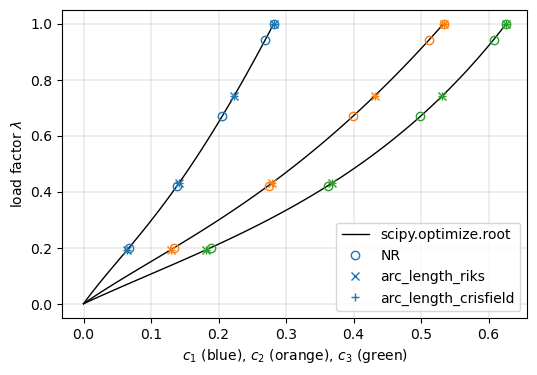

NR: max ||c - c_ref||/||c_ref|| over the increments = 7.58e-11
arc_length_riks: max ||c - c_ref||/||c_ref|| over the increments = 2.06e-11
arc_length_crisfield: max ||c - c_ref||/||c_ref|| over the increments = 1.15e-12

quantity                                                       computed         reference  rel. diff.
NR: ||c|| at lambda = 0.943 (worst)                        0.8389861812      0.8389861811    7.55e-11
arc_length_riks: ||c|| at lambda = 0.743 (worst)           0.7200093007      0.7200093006    2.06e-11
arc_length_crisfield: ||c|| at lambda = 0.743 (worst)      0.7200093006      0.7200093006    1.14e-12


In [3]:
def reference(pb, lbds, tol=1e-14):
    c = np.zeros(3)
    out = []
    for lbd in lbds:
        c = root(lambda x: pb.residual(x, lbd), c, method='hybr', tol=tol).x
        out.append(c)
    return np.array(out)


pb_ref = make_problem()
lbd_curve = np.linspace(0., 1., 101)
c_curve = reference(pb_ref, lbd_curve)

paths = {}
for method in ['NR', 'arc_length_riks', 'arc_length_crisfield']:
    pb = make_problem()
    an = pb.analysis(NL_method=method, initialInc=0.2)
    an.static(NLgeom=True, silent=True)
    paths[method] = (np.asarray(an.increments), np.asarray(an.cs))
    print(f'{method:22s}: {len(an.increments)} increments, '
          f'{len(pb.calls)} calls to calc_fint')

fig, ax = plt.subplots(figsize=(6, 4))
for i in range(3):
    ax.plot(c_curve[:, i], lbd_curve, 'k-', lw=1,
            label='scipy.optimize.root' if i == 0 else None)
for (method, (inc, cs)), mk in zip(paths.items(), ['o', 'x', '+']):
    for i in range(3):
        ax.plot(cs[:, i], inc, mk, mfc='none',
                color=f'C{i}', label=f'{method}' if i == 0 else None)
ax.set_xlabel('$c_1$ (blue), $c_2$ (orange), $c_3$ (green)')
ax.set_ylabel(r'load factor $\lambda$')
ax.grid(True, lw=0.3)
ax.legend()
plt.show()

rows = []
for method, (inc, cs) in paths.items():
    ref = reference(pb_ref, inc)
    err = np.linalg.norm(cs - ref, axis=1)/np.linalg.norm(ref, axis=1)
    i = np.argmax(err)
    rows.append((f'{method}: ||c|| at lambda = {inc[i]:.3f} (worst)',
                 np.linalg.norm(cs[i]), np.linalg.norm(ref[i])))
    print(f'{method}: max ||c - c_ref||/||c_ref|| over the increments = '
          f'{err.max():.2e}')
print()
print_table(rows)

### Quadratic convergence of Riks only with the load vector of the configuration

The bordered system of the Riks method is Newton's method applied to the
equilibrium equations augmented with the arc-length constraint only when
the load vector of the bordered system is the exact
$-\partial \boldsymbol{R}/\partial \lambda = \boldsymbol{q}_0 + \boldsymbol{Q} \boldsymbol{c}$,
i.e. when `calc_fext` accepts `c`. With the constant reference vector
$\boldsymbol{q}_0$, `calc_fext(inc)` without `c`, the Jacobian of the
augmented system is approximate and the iterations converge linearly. The
relative residuals $e_k = \|\boldsymbol{R}\|/\|\lambda \boldsymbol{q}\|$ of the
iterations of the first step, with `relTOL=1e-13`, and the convergence order
estimated as $\log(e_{k+1}/e_k)/\log(e_k/e_{k-1})$ in the asymptotic range,
$e_{k-1} < 5 \cdot 10^{-2}$ and $e_{k+1} > 10^{-12}$ (function `orders` of
`tests/test_follower_loads.py`), against the order 2 of Newton's method:

calc_fext with c: True : last load factor 1.0, 5 residual evaluations in the first step
calc_fext with c: False: last load factor 1.0, 13 residual evaluations in the first step


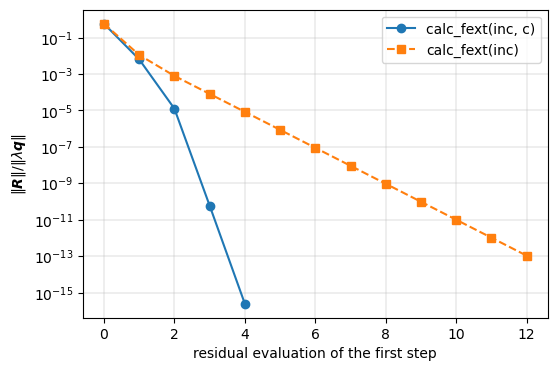

orders with c   : [1.967]
orders without c: [0.858 1.    1.001 1.    1.    1.    1.    1.    0.999]

quantity                                         computed         reference  rel. diff.
Riks, calc_fext(inc, c): smallest order       1.967337276                 2    1.63e-02


In [4]:
def orders(errors, floor=1e-12):
    return [np.log(e2/e1)/np.log(e1/e0)
            for e0, e1, e2 in zip(errors[:-2], errors[1:-1], errors[2:])
            if e2 > floor and e0 < 5e-2]


first_step = {}
for with_c in (True, False):
    pb = make_problem(with_c=with_c)
    an = pb.analysis(NL_method='arc_length_riks', initialInc=0.5,
                     relTOL=1e-13, maxNumIter=60)
    an.static(NLgeom=True, silent=True)
    # the first value is the residual of the tangent predictor
    first_step[with_c] = [e for inc, e, step in pb.calls if step == 0]
    print(f'calc_fext with c: {with_c!s:5}: last load factor '
          f'{an.increments[-1]}, {len(first_step[with_c])} residual '
          f'evaluations in the first step')

fig, ax = plt.subplots(figsize=(6, 4))
for with_c, errors in first_step.items():
    ax.semilogy(errors, 'o-' if with_c else 's--',
                label='calc_fext(inc, c)' if with_c else 'calc_fext(inc)')
ax.set_xlabel('residual evaluation of the first step')
ax.set_ylabel(r'$\|\boldsymbol{R}\| / \|\lambda \boldsymbol{q}\|$')
ax.grid(True, lw=0.3)
ax.legend()
plt.show()

p_c = orders(first_step[True])
print('orders with c   :', np.round(p_c, 3))
print('orders without c:', np.round(orders(first_step[False]), 3))
print()
print_table([('Riks, calc_fext(inc, c): smallest order', min(p_c), 2.)])

## Inertia of unsymmetric tangent stiffness matrices

The symmetric indefinite factorization of PARDISO counts the negative
eigenvalues of a symmetric tangent stiffness matrix (`Analysis.inertia` with
`linear_solver='pardiso'`); an unsymmetric one is factorized by SuperLU,
whose LU factorization gives only the sign of the determinant, the parity of
the number of negative real eigenvalues. With
`Analysis.inertia_num_eigvals = k`, the number of negative real eigenvalues
among the $k$ of smallest magnitude is computed at every converged increment
by shift-invert at $\sigma = 0$ with ARPACK, with the LU factorization of the
converged state, and recorded in `Analysis.num_negative_eigvals`, such that
`max_inertia_jump` applies, see
[newton_raphson._eigvals_inertia](../newton_raphson.rst).

It detects the divergence points, where a real eigenvalue crosses zero, the
static critical points of the path: limit points and bifurcations. It does
not detect flutter: a complex pair $a \pm i b$ whose real part becomes
negative is not a static critical point, the tangent staying regular, and it
is not counted (the number of such pairs among the $k$ is logged), the
kinetic criterion of [freq](../freq.rst) being needed, see below.
Negative real eigenvalues beyond the $k$ of smallest magnitude are missed;
an odd number of them is reported, since the parity of the count then
differs from the sign of the determinant.

The problem of the class `LinearUnsymmetric` of
`tests/test_inertia_unsymmetric.py` is linear in $\boldsymbol{c}$, with the
tangent stiffness matrix

$$
\boldsymbol{K}(\lambda) = \mathrm{diag}\left(k_0, \boldsymbol{S} (\boldsymbol{D}_0 + \lambda \boldsymbol{D}_1) \boldsymbol{S}^{-1}\right)
$$

unsymmetric and non-normal through the random $\boldsymbol{S}$, the load on
the degree of freedom 0, uncoupled from the others, such that the path is
$c_0 = \lambda/k_0$. The block diagonal $\boldsymbol{D}_0 + \lambda \boldsymbol{D}_1$
has two real eigenvalues that cross zero at $\lambda = 0.27$ and $0.63$, and
a complex pair whose real part crosses zero at $\lambda = 0.47$. The
reference count is that of the negative real eigenvalues of the dense
$\boldsymbol{K}(\lambda)$ by `numpy.linalg.eigvals`, among the 6 of smallest
magnitude and among all; the exact one is
$[\lambda > 0.27] + [\lambda > 0.63]$:

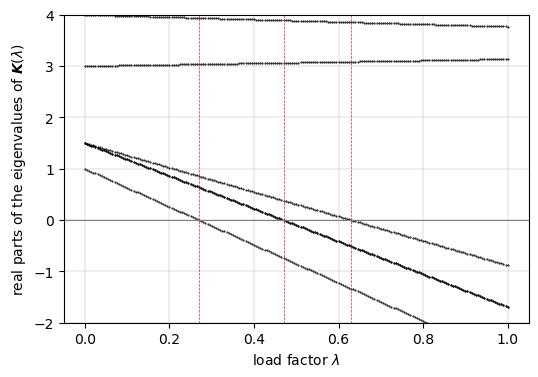


NR
  lambda  count  dense, 6  dense, all  exact  det sign
  0.1000      0         0           0      0         1
  0.2000      0         0           0      0         1
  0.3000      1         1           1      1        -1
  0.4000      1         1           1      1        -1
  0.5000      1         1           1      1        -1
  0.6000      1         1           1      1        -1
  0.7000      2         2           2      2         1
  0.8000      2         2           2      2         1
  0.9000      2         2           2      2         1
  1.0000      2         2           2      2         1



arc_length_riks
  lambda  count  dense, 6  dense, all  exact  det sign
  0.1000      0         0           0      0         1
  0.2000      0         0           0      0         1
  0.3000      1         1           1      1        -1
  0.4000      1         1           1      1        -1
  0.5000      1         1           1      1        -1
  0.6000      1         1           1      1        -1
  0.7000      2         2           2      2         1
  0.8000      2         2           2      2         1
  0.9000      2         2           2      2         1
  1.0000      2         2           2      2         1
  1.0000      2         2           2      2         1

arc_length_crisfield
  lambda  count  dense, 6  dense, all  exact  det sign
  0.1000      0         0           0      0         1
  0.2000      0         0           0      0         1
  0.3000      1         1           1      1        -1
  0.4000      1         1           1      1        -1
  0.5000      1         1 

In [5]:
p = LinearUnsymmetric([0.27, 0.63], complex_crossings=[0.47])
lbds = np.linspace(0., 1., 201)
lam = np.array([np.linalg.eigvals(p.K(l)) for l in lbds])
fig, ax = plt.subplots(figsize=(6, 4))
# the 8 lowest real parts at each load factor
real_sorted = np.sort(lam.real, axis=1)[:, :8]
ax.plot(lbds, real_sorted, 'k.', ms=1)
ax.axhline(0., color='gray', lw=0.8)
for lc in (0.27, 0.47, 0.63):
    ax.axvline(lc, color='C3', lw=0.5, ls='--')
ax.set_ylim(-2., 4.)
ax.set_xlabel(r'load factor $\lambda$')
ax.set_ylabel(r'real parts of the eigenvalues of $\boldsymbol{K}(\lambda)$')
ax.grid(True, lw=0.3)
plt.show()

for method in ['NR', 'arc_length_riks', 'arc_length_crisfield']:
    p = LinearUnsymmetric([0.27, 0.63], complex_crossings=[0.47])
    an = p.analysis(NL_method=method, inertia=True, inertia_num_eigvals=6,
                    linear_solver='splu', initialInc=0.1, maxInc=0.1)
    an.static(NLgeom=True, silent=True)
    print(f'\n{method}')
    print(f'{"lambda":>8}  {"count":>5}  {"dense, 6":>8}  {"dense, all":>10}'
          f'  {"exact":>5}  {"det sign":>8}')
    for lbd, nneg, det in zip(an.increments, an.num_negative_eigvals,
                              an.det_signs):
        print(f'{lbd:8.4f}  {nneg:5d}  {dense_count(p.K(lbd), 6):8d}  '
              f'{dense_count(p.K(lbd)):10d}  '
              f'{int(lbd > 0.27) + int(lbd > 0.63):5d}  {det:8d}')

The count goes 0, 1, 2 and agrees with the dense count at every increment,
whereas the sign of the determinant returns to +1 after the second
crossing (the arc-length paths have a converged point at
$\lambda = 1 - 10^{-16}$, printed as 1.0000, before the last one at exactly
1.0). The complex pair, whose real part is negative beyond
$\lambda = 0.47$, is not counted:

In [6]:
lam1 = np.linalg.eigvals(p.K(1.))
print('eigenvalues of K(1) with a negative real part:',
      np.round(lam1[lam1.real < 0], 4))

eigenvalues of K(1) with a negative real part: [-2.7037+0.j -1.6915+2.j -1.6915-2.j -0.881 +0.j]


## Linear static analysis

With a configuration-dependent load, `Analysis.static(NLgeom=False)` solves
the geometrically linear problem
$\boldsymbol{K}_{C0} \boldsymbol{c} = \boldsymbol{F}(\boldsymbol{c})$, here
with $\boldsymbol{F}(\boldsymbol{c}) = \boldsymbol{F}_0 + \boldsymbol{Q} \boldsymbol{c}$
and the random matrices of `linear_follower_problem` of
`tests/test_follower_freq_static.py`, $\boldsymbol{Q}$ scaled to 0.3 times
the critical load stiffness. The reference is the dense solution of
$(\boldsymbol{K}_{C0} - \boldsymbol{Q}) \boldsymbol{c} = \boldsymbol{F}_0$
by `numpy.linalg.solve`; without the keyword argument `c` in `calc_fext`
the load is the constant $\boldsymbol{F}_0$, and the reference
$\boldsymbol{K}_{C0} \boldsymbol{c} = \boldsymbol{F}_0$:

In [7]:
rows = []
for with_c in (True, False):
    pb = linear_follower_problem(with_c=with_c)
    an = pb.analysis()
    an.relTOL = 1e-12
    increments, cs = an.static(NLgeom=False, silent=True)
    A = pb.K0 - pb.Q if with_c else pb.K0
    ref = np.linalg.solve(A, pb.F0)
    label = 'F(c) = F0 + Q c' if with_c else 'F = F0'
    print(f'{label}: c   = {np.round(cs[0], 6)}')
    print(f'{label:15s}  ref = {np.round(ref, 6)}')
    rows.append((f'{label}: ||c||', np.linalg.norm(cs[0]),
                 np.linalg.norm(ref)))
    print(f'max |c - ref|/max |ref| = '
          f'{np.abs(cs[0] - ref).max()/np.abs(ref).max():.2e}\n')
print_table(rows)

F(c) = F0 + Q c: c   = [-0.092323  0.15736  -0.016753  0.130671 -0.060929 -0.121297]
F(c) = F0 + Q c  ref = [-0.092323  0.15736  -0.016753  0.130671 -0.060929 -0.121297]
max |c - ref|/max |ref| = 6.97e-13

F = F0: c   = [-0.074061  0.165399 -0.022207  0.114862 -0.064526 -0.123864]
F = F0           ref = [-0.074061  0.165399 -0.022207  0.114862 -0.064526 -0.123864]
max |c - ref|/max |ref| = 1.68e-16

quantity                        computed         reference  rel. diff.
F(c) = F0 + Q c: ||c||      0.2628053934      0.2628053934    2.92e-13
F = F0: ||c||               0.2569709412      0.2569709412    0.00e+00


## Linear buckling with unsymmetric matrices

[lb](../linear_buckling.rst) solves
$(\boldsymbol{K} + \lambda \boldsymbol{K}_G) \boldsymbol{u} = \boldsymbol{0}$.
A symmetric positive definite $\boldsymbol{K}$ of size 40 and an unsymmetric
$\boldsymbol{K}_G$, a symmetric negative definite matrix plus a small skew
part, which keeps the eigenvalues real; the reference is the dense
`scipy.linalg.eig` of $\boldsymbol{K}_G \boldsymbol{u} = \mu \boldsymbol{K} \boldsymbol{u}$,
$\lambda = -1/\mu$, for the sparse solver, the sparse solver without the
dense fallback (`max_dense_size=0`) and the dense solver:

In [8]:
def spd(n, rng):
    X = rng.standard_normal((n, n))
    return X @ X.T + n*np.eye(n)


rng = np.random.default_rng(3)
n = 40
K = spd(n, rng)
S = -spd(n, rng)/n
W = rng.standard_normal((n, n))
KG = S + 1e-3*(W - W.T)
print('KG symmetric:', is_symmetric(KG))

mu = eig(KG, K, right=False)
lam_ref = np.sort((-1/mu).real)
lam_ref = lam_ref[lam_ref > 0]

rows = []
for sparse_solver, max_dense_size in [(True, 2000), (True, 0), (False, 2000)]:
    eigvals, eigvecs = lb(csr_matrix(K), csr_matrix(KG), silent=True,
                          sparse_solver=sparse_solver, num_eigvalues=6,
                          max_dense_size=max_dense_size)
    res = relative_residuals(K, KG, eigvals[:5], eigvecs[:, :5])
    print(f'sparse_solver={sparse_solver}, max_dense_size={max_dense_size}: '
          f'real arrays {np.isrealobj(eigvals) and np.isrealobj(eigvecs)}, '
          f'max relative residual {res.max():.1e}')
    for i in range(5):
        rows.append((f'sparse={sparse_solver!s:5}, max_dense_size='
                     f'{max_dense_size:4d}: lambda_{i+1}', eigvals[i],
                     lam_ref[i]))
print()
print_table(rows)

KG symmetric: False
sparse_solver=True, max_dense_size=2000: real arrays True, max relative residual 3.3e-15
sparse_solver=True, max_dense_size=0: real arrays True, max relative residual 3.3e-15
sparse_solver=False, max_dense_size=2000: real arrays True, max relative residual 1.3e-15

quantity                                             computed         reference  rel. diff.
sparse=True , max_dense_size=2000: lambda_1       11.92188528       11.92188528    1.34e-15
sparse=True , max_dense_size=2000: lambda_2       12.57201198       12.57201198    4.10e-15
sparse=True , max_dense_size=2000: lambda_3       13.89536801       13.89536801    8.31e-15
sparse=True , max_dense_size=2000: lambda_4       14.70362176       14.70362176    1.21e-15
sparse=True , max_dense_size=2000: lambda_5       15.46914848       15.46914848    1.72e-15
sparse=True , max_dense_size=   0: lambda_1       11.92188528       11.92188528    1.34e-15
sparse=True , max_dense_size=   0: lambda_2       12.57201198       12

Under follower loads, many negative or complex load multipliers may have a
smaller modulus than the critical one, e.g. when the pressure is reversed.
The sparse solver of [lb](../linear_buckling.rst) searches the lowest
positive real load multiplier along the positive real axis, see
[Eigenvalue solvers](../eigensolvers.rst). The cantilevers of Schweizerhof
and Ramm (1984) under a follower pressure, with the matrices of
[panels](https://github.com/saullocastro/panels) saved in `tests/data`,
$\boldsymbol{K} = \boldsymbol{k}_0$ and
$\boldsymbol{K}_G = \boldsymbol{k}_G(\boldsymbol{c}_0) + \boldsymbol{k}_{C,follower}$,
original and reversed ($\pm \boldsymbol{K}_G$). The reference is the lowest
positive real load multiplier of the dense solver of all the eigenvalues,
`lb(..., sparse_solver=False)`; the sparse solver runs without the dense
fallback, `max_dense_size=0`:

In [9]:
rows = []
for name, sign, _ in FOLLOWER:
    K, KG = load_follower(name, sign)
    dense = lb(K, KG, silent=True, sparse_solver=False)[0]
    ref = lowest_positive_real(dense)
    finite = dense[np.isfinite(dense)]
    smaller = finite[np.abs(finite) < ref]
    eigvals, eigvecs = lb(K, KG, silent=True, max_dense_size=0)
    res = relative_residuals(K, KG, eigvals, eigvecs)
    print(f'{name}, sign {sign:+.0f}: size {K.shape[0]}, '
          f'{len(smaller)} load multipliers of modulus smaller than the '
          f'critical one, of which {np.sum(smaller.real < 0)} with a '
          f'negative real part; relative residual of the first eigenpair '
          f'{res[0]:.1e}')
    rows.append((f'{name}, sign {sign:+.0f}: lambda_cr', eigvals[0].real,
                 ref))
print()
print_table(rows)

s1B1_m14n8, sign +1: size 260, 0 load multipliers of modulus smaller than the critical one, of which 0 with a negative real part; relative residual of the first eigenpair 8.7e-13


s1B1_m14n8, sign -1: size 260, 66 load multipliers of modulus smaller than the critical one, of which 66 with a negative real part; relative residual of the first eigenpair 2.4e-13


s3B2_m14n8, sign +1: size 268, 0 load multipliers of modulus smaller than the critical one, of which 0 with a negative real part; relative residual of the first eigenpair 1.4e-11


s3B2_m14n8, sign -1: size 268, 66 load multipliers of modulus smaller than the critical one, of which 66 with a negative real part; relative residual of the first eigenpair 5.1e-13

quantity                                computed         reference  rel. diff.
s1B1_m14n8, sign +1: lambda_cr       1.862156984       1.862156984    4.56e-13
s1B1_m14n8, sign -1: lambda_cr        15113.4151        15113.4151    3.55e-11
s3B2_m14n8, sign +1: lambda_cr     0.05446120166     0.05446120166    9.74e-12
s3B2_m14n8, sign -1: lambda_cr       1161.443761       1161.443761    2.57e-10


## Flutter: the kinetic criterion

Ziegler's double pendulum (Ziegler, 1952), as in
`tests/test_follower_freq_static.py`: two rigid bars of length $l$,
rotational springs $k$ at the base and at the middle hinge, masses $2m$ at
the middle hinge and $m$ at the tip, and a follower force $P$ at the tip,
tangential to the upper bar. With the absolute rotations of the bars as
degrees of freedom,

$$
\boldsymbol{M} = m l^2 \begin{bmatrix} 3 & 1 \\ 1 & 1 \end{bmatrix}, \qquad
\boldsymbol{K}(P) = \begin{bmatrix} 2k - P l & -k + P l \\ -k & k \end{bmatrix}
$$

$\det \boldsymbol{K} = k^2$ for every $P$: the stiffness matrix is never
singular, and the static (divergence) criterion of
[lb](../linear_buckling.rst) finds no critical load. The natural
frequencies are the roots of
$\det(\boldsymbol{K} - \omega^2 \boldsymbol{M}) = 0$,

$$
2 m^2 l^4 \omega^4 - m l^2 (7k - 2Pl) \omega^2 + k^2 = 0
$$

real while the discriminant $m^2 l^4 \left[(7k - 2Pl)^2 - 8k^2\right]$ is
positive. They coalesce and become complex, flutter, at

$$
P_f = \left(\frac{7}{2} - \sqrt{2}\right) \frac{k}{l}
$$

the kinetic criterion of stability, the dynamic method of Bolotin (1963,
Introduction and Sections 6 and 7, pp. 12-17). [freq](../freq.rst)
returns $\lambda^2 = -\omega^2$, with its general eigenvalue solver for the
unsymmetric $\boldsymbol{K}$ (`ziegler` of the test module, with $k = 3$,
$l = 0.5$, $m = 2$):

P_f = 12.51471863
lb of K0 + P KF, dense solver, load multipliers: [-inf -inf]


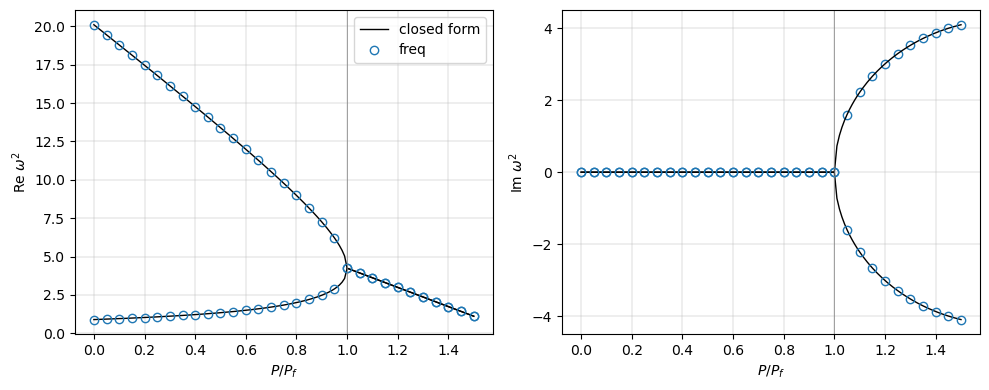

In [10]:
k, l, m = K_SPRING, L_BAR, MASS
P_F = (3.5 - np.sqrt(2))*k/l
print(f'P_f = {P_F:.10g}')

K0, _ = ziegler(0.)
K1, _ = ziegler(1.)
print('lb of K0 + P KF, dense solver, load multipliers:',
      lb(csr_matrix(K0), csr_matrix(K1 - K0), silent=True,
         sparse_solver=False)[0])


def omega2_exact(P):
    return np.sort(np.roots([2*m**2*l**4, -m*l**2*(7*k - 2*P*l),
                             k**2]).astype(complex))


Ps = np.linspace(0., 1.5*P_F, 151)
w2 = np.array([np.sort_complex(-freq(*map(csr_matrix, ziegler(P)),
                                     silent=True, sparse_solver=False,
                                     sort=False)[0]) for P in Ps])
w2_exact = np.array([omega2_exact(P) for P in Ps])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i in range(2):
    axes[0].plot(Ps/P_F, w2_exact[:, i].real, 'k-', lw=1,
                 label='closed form' if i == 0 else None)
    axes[0].plot(Ps[::5]/P_F, w2[::5, i].real, 'o', mfc='none', color='C0',
                 label='freq' if i == 0 else None)
    axes[1].plot(Ps/P_F, w2_exact[:, i].imag, 'k-', lw=1)
    axes[1].plot(Ps[::5]/P_F, w2[::5, i].imag, 'o', mfc='none', color='C0')
axes[0].set_ylabel(r'Re $\omega^2$')
axes[1].set_ylabel(r'Im $\omega^2$')
for ax in axes:
    ax.set_xlabel(r'$P/P_f$')
    ax.axvline(1., color='gray', lw=0.5)
    ax.grid(True, lw=0.3)
axes[0].legend()
fig.tight_layout()
plt.show()

The frequencies at $P = 0.5 P_f$ against the roots of the quadratic, and
the flutter load found by bisection on the onset of complex eigenvalues
(relative imaginary part above $10^{-6}$, 40 bisections between
$0.9 P_f$ and $1.1 P_f$), with the dense solver and with the sparse one, for
which 10 decoupled unit oscillators are added to the model (the sparse
solvers compute at most size - 2 eigenvalues):

In [11]:
def max_imag(lambda2):
    return np.max(np.abs(np.imag(lambda2)))


rows = []
lam2 = freq(*map(csr_matrix, ziegler(0.5*P_F)), silent=True,
            sparse_solver=False, sort=False)[0]
for i, (w2_num, w2_ref) in enumerate(zip(np.sort((-lam2).real),
                                         omega2_exact(0.5*P_F).real)):
    rows.append((f'omega_{i+1}^2 at P = 0.5 P_f', w2_num, w2_ref))

for sparse_solver, extra in [(False, 0), (True, 10)]:
    kw = dict(silent=True, sparse_solver=sparse_solver, num_eigvalues=4,
              sort=False)
    a, b = 0.9*P_F, 1.1*P_F
    for _ in range(40):
        c = 0.5*(a + b)
        lam2 = freq(*map(csr_matrix, ziegler(c, extra)), **kw)[0]
        if max_imag(lam2) > 1e-6*np.abs(lam2).max():
            b = c
        else:
            a = c
    rows.append((f'P_f, bisection, sparse_solver={sparse_solver}',
                 0.5*(a + b), P_F))
print_table(rows)

quantity                                     computed         reference  rel. diff.
omega_1^2 at P = 0.5 P_f                  1.343355214       1.343355214    3.31e-16
omega_2^2 at P = 0.5 P_f                  13.39928547       13.39928547    2.65e-16
P_f, bisection, sparse_solver=False       12.51471863       12.51471863    2.73e-13
P_f, bisection, sparse_solver=True        12.51471886       12.51471863    1.88e-08


The follower pressure loads of
[panels](https://github.com/saullocastro/panels) use all these features, see
`Shell.add_pressure_load(..., follower=True)`.